# Havayolu Yolcu Memnuniyeti Tahmini - Airline Satisfaction

Bu çalışmada Kaggle Playground Series S6E10 yarışmasındaki yolcu anketi verisini kullanıyoruz. Yolcunun yaşı, uçuş mesafesi, sınıfı ve uçuş içi hizmetlere verdiği puanlardan yolcunun memnun olup olmadığını tahmin edeceğiz.

In [1]:
import pandas as pd

In [2]:
train=pd.read_csv('train.csv')
test=pd.read_csv('test.csv')

In [3]:
train.shape, test.shape

((699635, 23), (299844, 22))

In [4]:
train.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [5]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   6996

In [6]:
train.describe()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,699635.000000,699635.000000,699635.000000,699635.000000,699635.00000,699635.00000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699635.000000,699343.000000
mean,349817.000000,39.001928,1353.778702,2.778722,3.15621,2.81324,3.013734,3.265644,3.364156,3.568950,3.453910,3.517404,3.472847,3.805443,3.420291,3.380401,1.176209,1.134280
std,201967.372129,13.800943,954.422566,1.280419,1.47539,1.32955,1.254014,1.300202,1.288538,1.275333,1.308157,1.238474,1.271755,1.079175,1.210604,1.277870,5.982187,5.749304
min,0.000000,7.000000,67.000000,0.000000,0.00000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,174908.500000,27.000000,631.000000,2.000000,2.00000,2.00000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,349817.000000,40.000000,954.000000,3.000000,3.00000,3.00000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000
75%,524725.500000,50.000000,1814.000000,4.000000,4.00000,4.00000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,4.000000,0.000000,0.000000
max,699634.000000,85.000000,4983.000000,5.000000,5.00000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,489.000000,491.000000


In [7]:
train.isnull().sum()[train.isnull().sum()>0]  # sadece Arrival Delay eksik

Arrival Delay in Minutes    292
dtype: int64

In [8]:
train['satisfaction'].value_counts()

satisfaction
False    389296
True     310339
Name: count, dtype: int64

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

<Axes: xlabel='satisfaction', ylabel='count'>

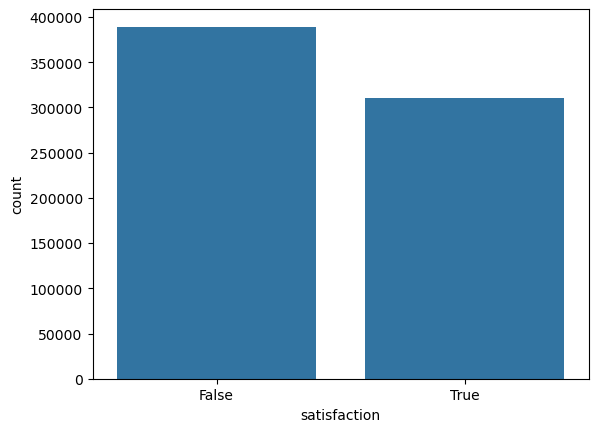

In [10]:
sns.countplot(x=train['satisfaction'])

<Axes: xlabel='Class', ylabel='count'>

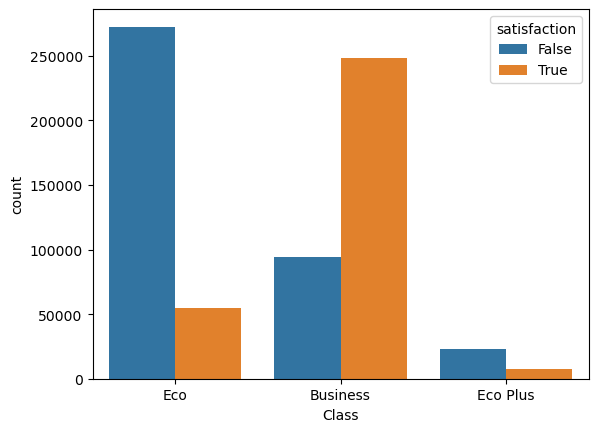

In [11]:
sns.countplot(x='Class', hue='satisfaction', data=train)

<Axes: xlabel='Type of Travel', ylabel='count'>

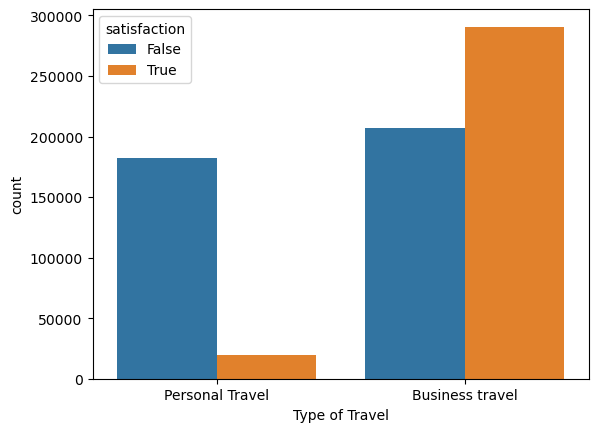

In [12]:
sns.countplot(x='Type of Travel', hue='satisfaction', data=train)

<Axes: xlabel='Customer Type', ylabel='count'>

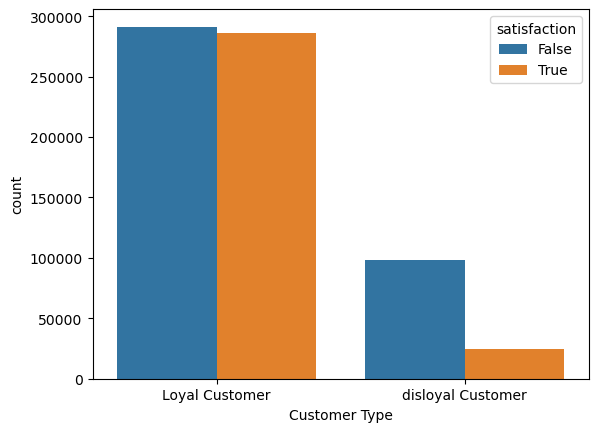

In [13]:
sns.countplot(x='Customer Type', hue='satisfaction', data=train)

<Axes: >

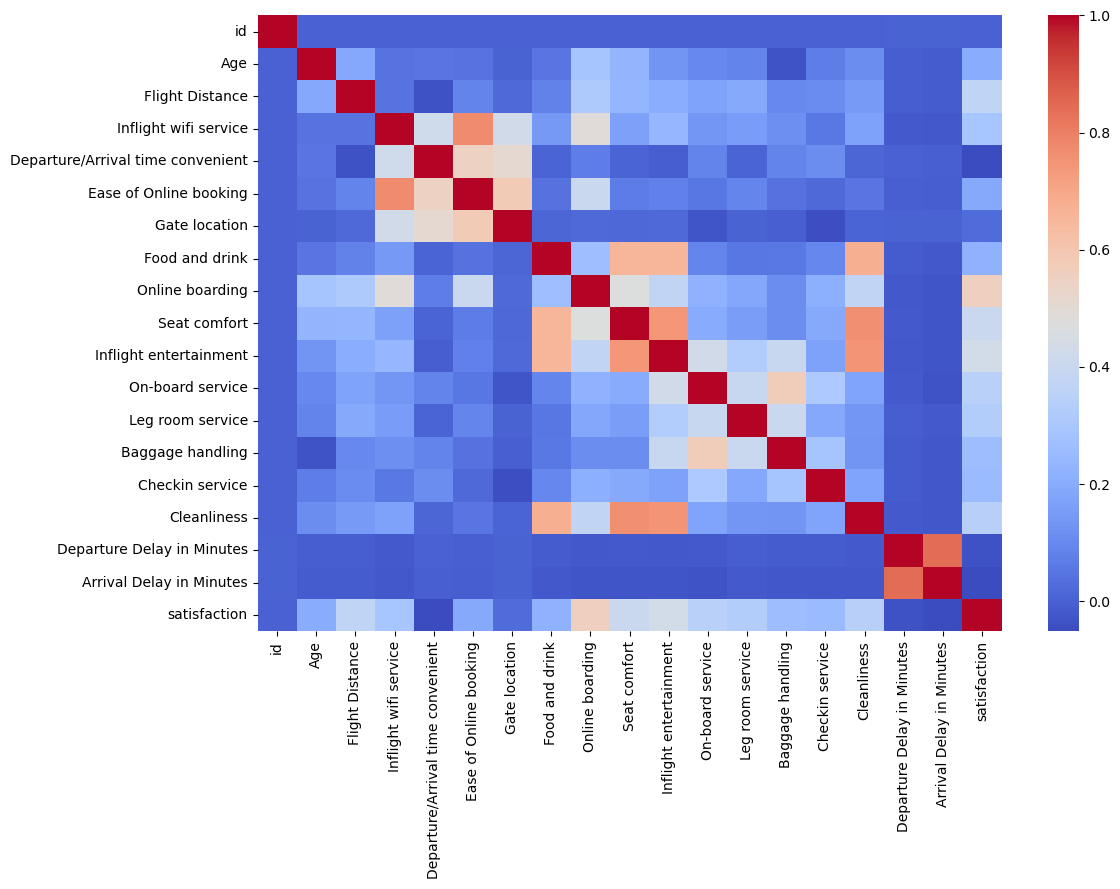

In [14]:
plt.figure(figsize=(12,8))
sns.heatmap(train.corr(numeric_only=True), cmap='coolwarm')

In [15]:
n=len(train)  # train satır sayısı

In [16]:
df=pd.concat([train.drop('satisfaction',axis=1),test],ignore_index=True)

In [17]:
df=df.drop('id',axis=1)

In [18]:
df['Arrival Delay in Minutes']=df['Arrival Delay in Minutes'].fillna(df['Arrival Delay in Minutes'].median())

In [19]:
df=pd.get_dummies(df,drop_first=True)

In [20]:
df.shape

(999479, 22)

In [21]:
x=df.iloc[:n]   # train kısmı
xt=df.iloc[n:]  # test kısmı

In [22]:
y=train['satisfaction'].astype(int)  # True/False -> 1/0

In [23]:
from sklearn.model_selection import train_test_split

In [24]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.20,random_state=42)

In [25]:
from sklearn.metrics import accuracy_score, roc_auc_score

In [26]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
xs_train=sc.fit_transform(x_train)  # sadece Logistic için ölçekliyoruz
xs_test=sc.transform(x_test)

In [27]:
from sklearn.linear_model import LogisticRegression
L=LogisticRegression(max_iter=1000)
L.fit(xs_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [28]:
p=L.predict_proba(xs_test)[:,1]
L_acc=accuracy_score(y_test,p>.5)
L_auc=roc_auc_score(y_test,p)
print(L_acc,L_auc)

0.8776147562657671 0.9213922618697221


In [29]:
from sklearn.tree import DecisionTreeClassifier
d=DecisionTreeClassifier(max_depth=10,random_state=42)
d.fit(x_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [30]:
p=d.predict_proba(x_test)[:,1]
d_acc=accuracy_score(y_test,p>.5)
d_auc=roc_auc_score(y_test,p)
print(d_acc,d_auc)

0.9143839287628549 0.9504187740708991


In [31]:
from sklearn.ensemble import RandomForestClassifier
r=RandomForestClassifier(n_estimators=100,max_depth=15,n_jobs=-1,random_state=42)
r.fit(x_train,y_train)  # birkaç dakika sürebilir

,n_estimators,100
,criterion,'gini'
,max_depth,15
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [32]:
p=r.predict_proba(x_test)[:,1]
r_acc=accuracy_score(y_test,p>.5)
r_auc=roc_auc_score(y_test,p)
print(r_acc,r_auc)

0.9228240439657821 0.9561609920886731


In [33]:
from sklearn.ensemble import HistGradientBoostingClassifier
g=HistGradientBoostingClassifier(max_iter=800,learning_rate=0.05,max_leaf_nodes=63,early_stopping=True,random_state=42)
g.fit(x_train,y_train)

,loss,'log_loss'
,learning_rate,0.05
,max_iter,800
,max_leaf_nodes,63
,max_depth,None
,min_samples_leaf,20
,l2_regularization,0.0
,max_features,1.0
,max_bins,255
,categorical_features,'from_dtype'
,monotonic_cst,None


In [34]:
p=g.predict_proba(x_test)[:,1]
g_acc=accuracy_score(y_test,p>.5)
g_auc=roc_auc_score(y_test,p)
print(g_acc,g_auc)

0.9252110028800732 0.9580688032627658


In [45]:
karsilastirma=pd.DataFrame({'model':['Logistic','Decision Tree','Random Forest','Gradient Boosting'],
                           'accuracy':[L_acc,d_acc,r_acc,g_acc],
                           'auc':[L_auc,d_auc,r_auc,g_auc]})

In [46]:
karsilastirma

,model,accuracy,auc
0,Logistic,0.877615,0.921392
1,Decision Tree,0.914384,0.950419
2,Random Forest,0.922824,0.956161
3,Gradient Boosting,0.925211,0.958069


In [36]:
model=HistGradientBoostingClassifier(max_iter=800,learning_rate=0.05,max_leaf_nodes=63,early_stopping=True,random_state=42)
model.fit(x,y)

,loss,'log_loss'
,learning_rate,0.05
,max_iter,800
,max_leaf_nodes,63
,max_depth,None
,min_samples_leaf,20
,l2_regularization,0.0
,max_features,1.0
,max_bins,255
,categorical_features,'from_dtype'
,monotonic_cst,None


In [37]:
tahmin=model.predict_proba(xt)[:,1]

In [38]:
sonuc=pd.DataFrame({'id':test['id'],'satisfaction':tahmin})

In [39]:
sonuc.to_csv('sonuc1.csv',index=False)

In [40]:
sonuc.head()

,id,satisfaction
0,699635,0.201407
1,699636,0.847601
2,699637,0.929211
3,699638,0.059090
4,699639,0.042510


In [41]:
sonuc.shape 

(299844, 2)

In [42]:
import pickle

In [43]:
pickle.dump(model,open('havayolu.pkl','wb'))
pickle.dump(list(x.columns),open('kolonlar.pkl','wb'))

In [47]:
kmodel=pickle.load(open('havayolu.pkl','rb'))
kmodel.predict_proba(x.iloc[[0]])[0][1] 

np.float64(0.24029550552940826)

### Sonuç

Bu çalışmada yolcu anketi verisiyle yolcunun memnun olup olmadığını tahmin ettik. Veride eksik değer neredeyse yoktu, sadece `Arrival Delay in Minutes` sütununda birkaç yüz boş satır vardı ve bunları medyanla doldurduk. Kategorik sütunları `get_dummies` ile sayıya çevirdik.

Dört modeli karşılaştırdık. Logistic Regression en zayıf sonucu verdi (AUC yaklaşık 0.92), Decision Tree ve Random Forest 0.95 civarına çıktı, Gradient Boosting ise yaklaşık 0.958 AUC ve **%92.5 doğrulukile en iyisi oldu. Bu da veride doğrusal olmayan ilişkiler olduğunu gösteriyor: hizmet puanları, seyahat türü ve sınıf birlikte etki ediyor.